# 第4週 NumPy 與 OpenCV 影像處理

**講師解答版：請勿於練習開始前發給學員。**

每週180分鐘，含10分鐘休息。每個W標號對應PPT與Word同一單元。

教材對照：CH09PPT 9-1；CH10PPT 10-1、10-2、10-4；10-3 視訊列延伸

學習目標：
- 能描述影像的高、寬與通道
- 能正確轉換BGR與RGB並剪裁
- 能以函數完成灰階、縮放及存檔

先按Shift+Enter逐格執行；交件前重新啟動核心並全部執行。練習格預設以註解保存，請取消註解後完成。請勿將未完成的函數覆蓋示範函數後繼續執行。

## 課前套件
由講師先依總覽安裝套件。核心程式不下載模型或開啟攝影機；色卡由程式自行產生。輸出檔案寫在目前工作目錄的outputs資料夾。

In [1]:
import sys
print("Python", sys.version.split()[0])

Python 3.12.14


## W4-01 影像也是資料

000–010 分鐘，10分鐘。

- 一張影像由像素組成
- 每個像素可包含三個通道
- 今日用內建色塊圖練習

**操作任務**：指出圖片的高、寬與顏色，回想串列索引從幾開始。

**參考答案與驗收**：索引從0開始；影像shape按高、寬、通道排列。

## W4-02 環境與套件

010–025 分鐘，15分鐘。

- NumPy 管理陣列
- OpenCV 處理影像
- Pillow 協助 Notebook 內嵌顯示

**操作任務**：執行環境格，確認可匯入numpy、cv2及PIL。

In [2]:
import sys
import numpy as np
import cv2
from PIL import Image
from IPython.display import display
from pathlib import Path
print("Python", sys.version.split()[0])
print("NumPy", np.__version__)
print("OpenCV", cv2.__version__)

Python 3.12.14
NumPy 2.2.6
OpenCV 4.12.0


**參考答案與驗收**：印出三個版本，且沒有ModuleNotFoundError。

## W4-03 建立彩色陣列

025–045 分鐘，20分鐘。

- shape 是高、寬、通道
- uint8 像素值範圍0到255
- 列先於欄，y先於x

**操作任務**：印出shape與左上像素，指出為何左上紅色在BGR表示為[0,0,255]。

In [3]:
bgr = np.zeros((120, 180, 3), dtype=np.uint8)
bgr[:, :60] = [0, 0, 255]
bgr[:, 60:120] = [0, 255, 0]
bgr[:, 120:] = [255, 0, 0]
print(bgr.shape, bgr.dtype, bgr[0, 0])

(120, 180, 3) uint8 [  0   0 255]


### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

In [4]:
assert bgr.shape == (120, 180, 3)
assert bgr[0, 70].tolist() == [0, 255, 0]
print(bgr[0, 70])

[  0 255   0]


**參考答案與驗收**：shape=(120,180,3)，BGR紅色是[0,0,255]。

## W4-04 BGR 與 RGB

045–060 分鐘，15分鐘。

- OpenCV 彩色讀檔預設BGR
- Pillow 顯示採RGB
- 轉換順序不會改變影像尺寸

**操作任務**：顯示轉換前與轉換後圖像，指出哪一張符合左紅中綠右藍。

未轉換，紅藍會交換


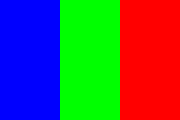

正確RGB


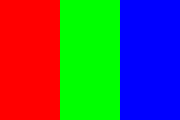

In [5]:
print("未轉換，紅藍會交換")
display(Image.fromarray(bgr))
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
print("正確RGB")
display(Image.fromarray(rgb))

### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

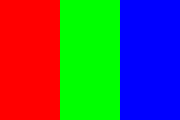

In [6]:
correct_rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
assert correct_rgb[0, 0].tolist() == [255, 0, 0]
display(Image.fromarray(correct_rgb))

**參考答案與驗收**：轉成RGB後的圖符合指定顏色；shape維持(120,180,3)。

## W4-05 休息與畫面確認

060–070 分鐘，10分鐘。

- 休息10分鐘
- 確認左紅中綠右藍
- 存檔再離開座位

**操作任務**：存檔與休息。

**參考答案與驗收**：保留正確色塊輸出。

## W4-06 剪裁與複製

070–090 分鐘，20分鐘。

- img[y1:y2, x1:x2]
- 切片不含結束位置
- copy 避免修改原圖

**操作任務**：剪裁所有列、欄60到120，確認全綠且寬60。

(120, 60, 3)


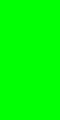

In [7]:
crop = rgb[:, 60:120].copy()
print(crop.shape)
display(Image.fromarray(crop))

### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

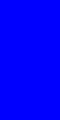

In [8]:
blue_crop = rgb[:, 120:180].copy()
assert blue_crop.shape == (120, 60, 3)
assert blue_crop[0, 0].tolist() == [0, 0, 255]
display(Image.fromarray(blue_crop))

**參考答案與驗收**：shape=(120,60,3)，RGB像素[0,255,0]。

## W4-07 縮放與灰階

090–110 分鐘，20分鐘。

- resize 尺寸參數先寬後高
- 灰階影像常是二維陣列
- 灰階值不是簡單取某一通道

**操作任務**：縮成寬90高60，再轉灰階，記錄兩個shape。

(60, 90, 3) (60, 90)


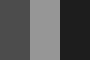

In [9]:
small_bgr = cv2.resize(bgr, (90, 60))
gray = cv2.cvtColor(small_bgr, cv2.COLOR_BGR2GRAY)
print(small_bgr.shape, gray.shape)
display(Image.fromarray(gray))

### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

In [10]:
small = cv2.resize(bgr, (60, 40))
assert small.shape == (40, 60, 3)
print(small.shape)

(40, 60, 3)


**參考答案與驗收**：彩色(60,90,3)，灰階(60,90)。

## W4-08 檔案讀寫與路徑

110–125 分鐘，15分鐘。

- 寫檔後確認成功
- 讀檔失敗會得到None
- 中文路徑可用位元組解碼

**操作任務**：儲存color_blocks.png再讀回，比對shape與像素。

In [11]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
image_path = output_dir / "color_blocks.png"
ok, encoded = cv2.imencode(".png", bgr)
if not ok:
    raise RuntimeError("PNG編碼失敗")
image_path.write_bytes(encoded.tobytes())
loaded = cv2.imdecode(np.frombuffer(image_path.read_bytes(), dtype=np.uint8), cv2.IMREAD_COLOR)
if loaded is None:
    raise ValueError("無法讀取影像")
print(loaded.shape, np.array_equal(loaded, bgr))

(120, 180, 3) True


### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

In [12]:
assert image_path.exists()
assert np.array_equal(loaded, bgr)
print("讀寫一致")

讀寫一致


**參考答案與驗收**：解碼成功，shape及像素與原bgr相同。

## W4-09 閾值與規則處理

125–140 分鐘，15分鐘。

- threshold 依亮度切成黑白
- 門檻由人指定
- 影像處理不等於已訓練AI

**操作任務**：比較門檻50、120、200；用np.unique檢查黑白值。

[  0 255]


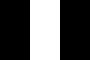

In [13]:
_, binary = cv2.threshold(gray, 120, 255, cv2.THRESH_BINARY)
print(np.unique(binary))
display(Image.fromarray(binary))

### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

In [14]:
_, binary_200 = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY)
assert np.count_nonzero(binary_200) <= np.count_nonzero(binary)
print(np.count_nonzero(binary_200))

0


**參考答案與驗收**：輸出值只可能0或255；門檻越高，白色像素不會增加。

## W4-10 本週實作 影像處理函數

140–160 分鐘，20分鐘。

- 函數接收BGR影像
- 縮放、灰階、二值化
- 回傳結果並保存

**操作任務**：完成preprocess；保存binary.png，測試門檻120與200。

In [15]:
print("本週專題：請完成下方函數")

本週專題：請完成下方函數


### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

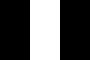

In [16]:
def preprocess(image_bgr, threshold_value=120):
    resized = cv2.resize(image_bgr, (90, 60))
    gray_image = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    _, result = cv2.threshold(gray_image, threshold_value, 255, cv2.THRESH_BINARY)
    return result

result = preprocess(bgr)
assert result.shape == (60, 90)
assert set(np.unique(result)).issubset({0, 255})
Image.fromarray(result).save(output_dir / "binary.png")
display(Image.fromarray(result))
assert np.count_nonzero(preprocess(bgr, 200)) <= np.count_nonzero(result)

**參考答案與驗收**：兩者shape=(60,90)，像素只含0或255；讀回binary.png應成功。

## W4-11 影像檢核與除錯

160–170 分鐘，10分鐘。

- 顏色以已知像素驗證
- 尺寸用shape驗證
- 裁切空陣列先檢查範圍

**操作任務**：同桌檢查色塊方向、函數輸出shape與保存檔案。

**參考答案與驗收**：左紅中綠右藍；黑白圖(60,90)；outputs/binary.png存在。

## W4-12 離堂題與課後練習

170–180 分鐘，10分鐘。

- shape 與 resize 的順序
- RGB 與 BGR 的差別
- 下週從資料建立分類器

**操作任務**：使用自製色塊圖測試流程並記錄shape，避免使用人臉或個資照片。

**參考答案與驗收**：shape高120寬180通道3；resize寬90高60；閾值由人指定。

## 課後作業參考解
以下為獨立解答，請在學員完成作業後提供。

(60, 90)


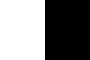

In [17]:
custom_bgr = np.zeros((40, 60, 3), dtype=np.uint8)
custom_bgr[:, :30] = [0, 255, 0]
custom_result = preprocess(custom_bgr)
print(custom_result.shape)
display(Image.fromarray(custom_result))

## 章後習題與詳解補充教材

本段依本週課綱整理，供課後複習與延伸練習，不列入原定180分鐘必做進度。

題目來源：全華《看圖學Python人工智慧程式設計》「中文習題WORD檔(全).doc」。解答來源：「章後習題詳解(全).doc」（文件標示2022/8/1）。保留原章號與題號，逐題配對；原解僅引用課本時保留章節指引。

「原詳解」保留來源內容；「教學補充與勘誤」是本次整理新增。原解中的舊版套件範例須另備教材檔案、相符套件或攝影機；Markdown 內的範例不會隨「全部執行」自動執行。

講師版：每題後直接列出解答，方便講解與核對。

本週章節：第10章。

第9章模組匯入可回看第3週第9章第1、2題。



### 第10章：OpenCV影像處理與Webcam

#### 第10章 第1題

請說明什麼是OpenCV？OpenCV如何處理Webcam攝影機？

**原詳解**

OpenCV（Open Source Computer Vision Library）是一套跨平台BSD授權的電腦視覺庫（Computer Vision Library），這是英特爾公司發起並參與開發，可以幫助我們開發影像處理、電腦視覺的人臉偵測和物體辨識等人工智慧的相關應用。

請參閱第10-3-2節的說明。



#### 第10章 第2題

請問OpenCV如何在影像繪圖和加上文字？什麼是imutils套件？

**原詳解**

請參閱第10-2-3節的說明。

除了使用OpenCV內建功能外，imutils套件提供相關方法，可以讓我們更容易執行OpenCV影像處理。



#### 第10章 第3題

請問什麼是影像幾何轉換？何謂色彩空間？

**原詳解**

影像幾何轉換是針對影像內容的影像進行縮放、翻轉、剪裁、旋轉和位移等操作。

色彩空間是數位影像描述色彩的方法，我們可以使用色彩三原色紅、綠和藍色來描述，即RGB格式，除此之外，還有BGR、HSV、HIS和HSL等多種色彩格式。



#### 第10章 第4題

請說明什麼是NumPy陣列？NumPy陣列和Python串列的差異？

**原詳解**

OpenCV使用imread()方法讀取的影像是NumPy陣列，NumPy套件全名是Numeric Python或Numerical Python，提供一維、二維和多維陣列物件，支援高效率陣列的數學、邏輯、維度操作、排序、選取元素，和基本線性代數與統計等。

NumPy陣列（Arrays）類似Python串列（Lists），不過陣列元素的資料型態必須是相同的。NumPy套件的核心是ndarray物件，這是一序列的整數int或浮點數float值，每一個值的陣列元素都是相同的資料型態。



#### 第10章 第5題

請建立Python程式讀取"cat.jpg"圖檔後，轉換成灰階和旋轉90度，最後在影像上寫上你的名字。

**原詳解**

```text
Import cv2
import imutils

img = cv2.imread("cat.jpg", cv2.IMREAD_GRAYSCALE)
rotated_img = imutils.rotate(img, angle=90)
cv2.putText(rotated_img, 'Joe Chen', (10, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            1, (0,255,255), 5, cv2.LINE_AA)
cv2.imshow("Cat:gray", rotated_img)
```

**教學補充與勘誤**

原解 Import 應為小寫 import。Notebook 使用 matplotlib 顯示影像；灰階影像文字色彩用單一數值，旋轉採不裁切的90度旋轉。需先準備 cat.jpg。

```python
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("cat.jpg", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("請先準備 cat.jpg")
rotated_img = cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE)
cv2.putText(rotated_img, "Your Name", (10, 40),
            cv2.FONT_HERSHEY_SIMPLEX, 1, 255, 2, cv2.LINE_AA)
plt.imshow(rotated_img, cmap="gray")
plt.axis("off")
plt.show()
```



#### 第10章 第6題（延伸練習）

請建立Python程式使用灰階播放"YouTube.mp4"視訊檔，然後寫入視訊檔，換句話說，就是將彩色視訊檔轉換成灰階視訊檔。

**原詳解**

```text
import cv2 

cap = cv2.VideoCapture("YouTube.mp4") 

frame_width = int(cap.get(3)) 
frame_height = int(cap.get(4)) 
size = (frame_width, frame_height) 
result = cv2.VideoWriter('gray.avi',  
            cv2.VideoWriter_fourcc(*'MJPG'), 
            10, size, 0) 
while True: 
    ret, img = cap.read() 
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) 
    result.write(gray)
    cv2.imshow("Live", gray) 
   key = cv2.waitKey(1) 
    if key == ord("q"): 
        break

cv2.destroyAllWindows() 
cap.release()
```

**教學補充與勘誤**

原解未檢查讀取成功、key 行縮排錯誤，也未釋放 VideoWriter。以下為桌面環境修正版，需 YouTube.mp4 與可開啟視窗的 OpenCV；不適用無視窗的雲端 Notebook。

```python
import cv2

cap = cv2.VideoCapture("YouTube.mp4")
writer = None
try:
    if not cap.isOpened():
        raise FileNotFoundError("無法開啟 YouTube.mp4")
    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps <= 0:
        fps = 10.0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        if writer is None:
            h, w = gray.shape
            writer = cv2.VideoWriter("gray.avi", cv2.VideoWriter_fourcc(*"MJPG"), fps, (w, h), False)
            if not writer.isOpened():
                raise RuntimeError("無法建立 gray.avi")
        writer.write(gray)
        cv2.imshow("Gray", gray)
        if cv2.waitKey(max(1, round(1000 / fps))) & 0xFF == ord("q"):
            break
finally:
    cap.release()
    if writer is not None:
        writer.release()
    cv2.destroyAllWindows()
```



#### 第10章 第7題

請寫出Python程式使用串列建立NumPy陣列，其輸出結果如下所示：:

串列: [12.23, 13.32, 100, 36.32]

一維陣列:  [ 12.23  13.32 100.    36.32]

**原詳解**

```text
import numpy as np

lst = [12.23, 13.32, 100, 36.32]
print("串列:", lst)
a = np.array(lst)
print("一維陣列: ", a)
```



#### 第10章 第8題

請寫出Python程式建立一維NumPy陣列[4,5,2,3,1,6,7,8,9,11,15,34]，在轉換成(3, 4)形狀的陣列後，將每一個元素乘以3後，顯示新陣列的內容，最後再平坦化成一維陣列和顯示出來。

**原詳解**

```text
import numpy as np

lst = [4,5,2,3,1,6,7,8,9,11,15,34]
a = np.array(lst)
x =  a.reshape(3, 4)
print(x)
b = x * 3
print(b)
c = b.flatten()
print(c)
```



### Copilot 輔助學習

先自行作答，再請 Copilot 解釋程式、提出邊界測試並與本段原詳解及勘誤比對。以下提示詞是教材內容，供學員自行複製使用。

#### 本週延伸提示詞（本次新增）

提供的 Copilot 資料夾僅有第1至9章，以下為配合本週主題新增的提示詞。

```text
請依第10章第8題，說明reshape前後元素總數為何必須一致，列出乘以3後的矩陣與flatten結果，再提出一個形狀不合法的反例。
```